# Day 28 | Turn a Webpage Into Useful Text

**KGP Talkie**

Read HTML, remove page clutter, and extract the facts we need.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

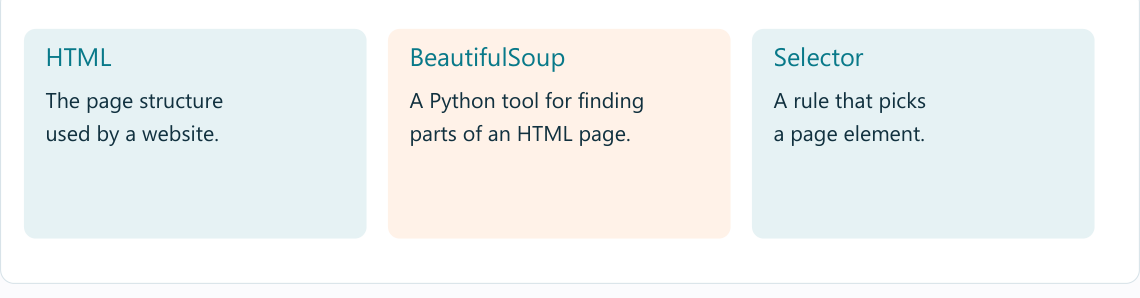

In [4]:
from bs4 import BeautifulSoup

In [5]:
raw = (ASSETS / "workshop.html").read_text(encoding="utf-8")

In [6]:
soup = BeautifulSoup(raw, "html.parser")

All text includes menu and footer words. Inspect them before filtering.

In [7]:
print(soup.get_text(" ", strip=True))

Home Login Workshop Python starts at 10:00. Pandas starts at 11:00. Class Room Python 2 Pandas 3 Subscribe


The selector chooses the main HTML element, which contains our class information.

In [8]:
main = soup.select_one("main")

A separator keeps neighboring pieces apart; strip removes outer spaces.

In [9]:
cleaned = main.get_text("\n", strip=True)
print(cleaned)

Workshop
Python starts at 10:00.
Pandas starts at 11:00.
Class
Room
Python
2
Pandas
3


ChatOllama sends chat requests to the local Ollama server.

In [10]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [11]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [12]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [13]:
print(llm.invoke(f"Use only this text: {cleaned}\nWhen does Pandas start?").content)

According to the text, Pandas starts at 11:00.


In [14]:
updated = cleaned.replace("11:00", "12:00")

A fresh source change should change the answer. This is a snapshot exercise, not a live webpage request.

In [15]:
print(llm.invoke(f"Use only this updated text: {updated}\nWhen does Pandas start?").content)

According to the provided text, Pandas starts at 12:00.


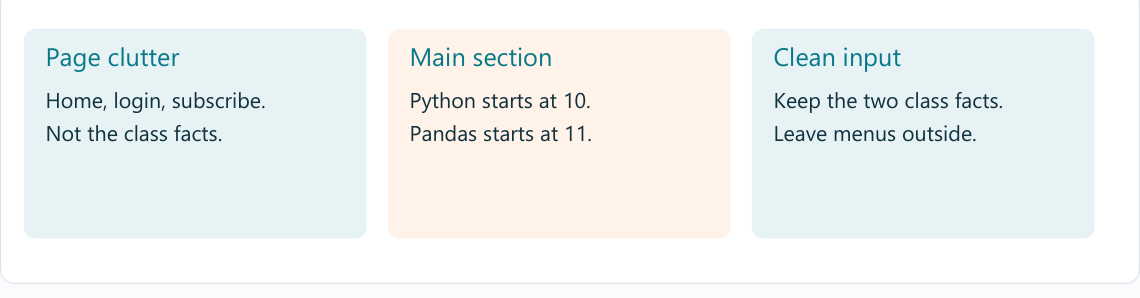

## Try a fresh input

Ask a question from the cleaned text. Change the snapshot and run again to see why stale content gives stale answers.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-document-loaders).